## Loading the ontology

In [3]:
from pathlib import Path

from rdflib import OWL, RDF, RDFS, Graph, Namespace, URIRef

BASE_DIR = Path.cwd().parent
ONTOLOGY_PATH = BASE_DIR / "data" / "wittgenstein.owl"

if not ONTOLOGY_PATH.exists():
    raise FileNotFoundError(f"Ontology file not found: {ONTOLOGY_PATH}")

graph = Graph()
graph.parse(str(ONTOLOGY_PATH))

WAB = Namespace("http://purl.org/wittgensteinsource/ont/")
print(f"Loaded triples: {len(graph):,}")


Loaded triples: 749,032


## Inspecting the relevant class

In [4]:
part_class = WAB.Part

print("Class: ", part_class)
print("label: ", graph.value(part_class, RDFS.label))
print("comment: ", graph.value(part_class, RDFS.comment))

for parent in graph.objects(part_class, RDFS.subClassOf):
    print("SubClassOf: ", parent)

part_instances = list(graph.subjects(RDF.type, part_class))
print(f"number of Part instances: {len(part_instances):,}")

Class:  http://purl.org/wittgensteinsource/ont/Part
label:  Part
comment:  Part
SubClassOf:  http://purl.org/wittgensteinsource/ont/WittgensteinSource
number of Part instances: 7,881


## inspect a small sample of Part instances

In [5]:
def guess_work_from_label(label):
    if " (" in label:
        return label.split(" (")[0]
    return label


def get_label(thing):
    label = graph.value(thing, RDFS.label)
    return str(label) if label else ""


relation_names = [
    WAB.isPartOf,
    WAB.isWorkPublishedFrom,
    WAB.isPublishedInWork,
    WAB.hasPart,
]

seen_works = set()
shown = 0

for instance in part_instances:
    label = get_label(instance)
    if not label:
        continue

    work = guess_work_from_label(label)
    if work in seen_works:
        continue
    seen_works.add(work)

    print(f"\nLabel: {label}")
    print(f"URI: {instance}")

    for predicate in relation_names:
        short = predicate.split("/")[-1]
        for obj in graph.objects(instance, predicate):
            print(f"  outgoing: {short} -> {obj}")
        for subject in graph.subjects(predicate, instance):
            print(f"  incoming: {short} <- {subject}")

    
    shown += 1
    if shown >= 10:
        break

print(f"\nDistinct works shown: {shown}")


Label: Prototractatus (PT, eds. 1971 McGuinness, Nyberg et von Wright) 0
URI: http://purl.org/wittgensteinsource/ont/instances/W-PT%3A%200
  outgoing: isPartOf -> http://purl.org/wittgensteinsource/ont/instances/W-PT
  outgoing: isWorkPublishedFrom -> http://wittgensteinsource.org/Ms-104%2CIII%5B1%5D_d
  outgoing: isWorkPublishedFrom -> http://wittgensteinsource.org/Ms-104%2CV%5B1%5D_d
  outgoing: isWorkPublishedFrom -> http://wittgensteinsource.org/Ms-104%2CVI%5B1%5D_d
  outgoing: isWorkPublishedFrom -> http://wittgensteinsource.org/Ms-104%2C1%5B1%5D_d
  outgoing: isWorkPublishedFrom -> http://wittgensteinsource.org/Ms-104%2C119%5B1%5Det120%5B1%5Det121%5B1%5D_d
  incoming: isPublishedInWork <- http://wittgensteinsource.org/Ms-104%2CIII%5B1%5D_d
  incoming: isPublishedInWork <- http://wittgensteinsource.org/Ms-104%2CV%5B1%5D_d
  incoming: isPublishedInWork <- http://wittgensteinsource.org/Ms-104%2CVI%5B1%5D_d
  incoming: isPublishedInWork <- http://wittgensteinsource.org/Ms-104%2C1%5B

## Inspecting proposition 6.23

In [6]:
from rdflib import Literal

target_label = "Tractatus logico-philosophicus (TLP, 1922 et 1933) 6.23"
target_matches = list(graph.subjects(RDFS.label, Literal(target_label)))

print("Matches:", len(target_matches))
for target in target_matches:
    print("WAB individual:", target)
    print("  type:", graph.value(target, RDF.type))
    print("  label:", graph.value(target, RDFS.label))
    for parent in graph.objects(target, WAB.isPartOf):
        print("  isPartOf ->", parent)
    for source in graph.objects(target, WAB.isWorkPublishedFrom):
        print("  isWorkPublishedFrom ->", source)
    for container in graph.subjects(WAB.hasPart, target):
        print("  incoming hasPart <-", container)

Matches: 1
WAB individual: http://purl.org/wittgensteinsource/ont/instances/W-TLP%3A%206.23
  type: http://purl.org/wittgensteinsource/ont/Part
  label: Tractatus logico-philosophicus (TLP, 1922 et 1933) 6.23
  isPartOf -> http://purl.org/wittgensteinsource/ont/instances/W-TLP
  isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-202%2C46r%5B8%5D_d
  isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-203%2C50r%5B3%5D_d
  isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-204%2C46r%5B8%5D_d
  incoming hasPart <- http://purl.org/wittgensteinsource/ont/instances/W-TLP


## Checking language and text sources

In [7]:
from rdflib import Literal

english_literals = []

for subject, predicate, obj in graph:
    if isinstance(obj, Literal) and obj.language:  # noqa: SIM102
        if obj.language.lower().startswith("en"):
            english_literals.append(
                (subject, predicate, obj)
            )

print("English-tagged literals:", len(english_literals))

for subject, predicate, obj in english_literals[:30]:
    print("\nSubject:", subject)
    print("Property:", predicate)
    print("Text:", obj)

English-tagged literals: 1

Subject: http://purl.org/wittgensteinsource/ont/hasVariant
Property: http://www.w3.org/2000/01/rdf-schema#comment
Text: A property for stating that a Bemerkung is or contains a variant of another 
Bemerkung.


In [8]:
from rdflib import URIRef

target = URIRef(
    "http://purl.org/wittgensteinsource/ont/instances/W-TLP%3A%206.23"
)

print("outgoing triples:")
for s, p, o in graph.triples((target, None, None)):
    print(f"{p.split("/")[-1]} -> {o}")

print("incoming triples:")
for s, p, o in graph.triples((None, None, target)):
    print(f"{s} -{p.split("/")[-1]}->target")

outgoing triples:
22-rdf-syntax-ns#type -> http://purl.org/wittgensteinsource/ont/Part
rdf-schema#label -> Tractatus logico-philosophicus (TLP, 1922 et 1933) 6.23
isPartOf -> http://purl.org/wittgensteinsource/ont/instances/W-TLP
isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-202%2C46r%5B8%5D_d
isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-203%2C50r%5B3%5D_d
isWorkPublishedFrom -> http://wittgensteinsource.org/Ts-204%2C46r%5B8%5D_d
incoming triples:
http://purl.org/wittgensteinsource/ont/instances/W-TLP -hasPart->target
http://wittgensteinsource.org/Ts-202%2C46r%5B8%5D_d -isPublishedInWork->target
http://wittgensteinsource.org/Ts-203%2C50r%5B3%5D_d -isPublishedInWork->target
http://wittgensteinsource.org/Ts-204%2C46r%5B8%5D_d -isPublishedInWork->target


In [9]:
from rdflib import RDF, RDFS, Namespace

print("Statements about the class Part:")
for triple in graph.triples((part_class, None, None)):
    print(triple)

print("\nStatements referring to Part (first 20):")
shown = 0
for triple in graph.triples((None, None, part_class)):
    print(triple)
    shown += 1
    if shown >= 20:
        break

print(f"\n... and {len(part_instances) - shown:,} more")
print(f"Total Part instances: {len(part_instances):,}")

Statements about the class Part:
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/1999/02/22-rdf-syntax-ns#type'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#Class'))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#comment'), rdflib.term.Literal('Part', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#subClassOf'), rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/WittgensteinSource'))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#label'), rdflib.term.Literal('Part', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')))

Statements referring to Part (first 20):
(rdflib.term.BNode('N80a15c1

In [10]:
print("Statements about the class Part:")
for triple in graph.triples((part_class, None, None)):
    print(triple)

print("\nStatements referring to Part (first 20):")
shown = 0
for triple in graph.triples((None, None, part_class)):
    print(triple)
    shown += 1
    if shown >= 20:
        break

print(f"\n... and {len(part_instances) - shown:,} more")
print(f"Total Part instances: {len(part_instances):,}")

Statements about the class Part:
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/1999/02/22-rdf-syntax-ns#type'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#Class'))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#comment'), rdflib.term.Literal('Part', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#subClassOf'), rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/WittgensteinSource'))
(rdflib.term.URIRef('http://purl.org/wittgensteinsource/ont/Part'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#label'), rdflib.term.Literal('Part', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')))

Statements referring to Part (first 20):
(rdflib.term.BNode('N80a15c1

exploring ontology classes

In [11]:
declared_classes = set()
for c in graph.subjects(RDF.type, OWL.Class):
    declared_classes.add(c)
for c in graph.subjects(RDF.type, RDFS.Class):
    declared_classes.add(c)

counts = {}
for subject, class_uri in graph.subject_objects(RDF.type):
    if class_uri in declared_classes:
        if class_uri in counts:
            counts[class_uri] += 1
        else:
            counts[class_uri] = 1

sorted_items = sorted(counts.items(), key=lambda pair: pair[1], reverse=True)

print("Number of classes with instances:", len(counts))
for class_uri, count in sorted_items:
    label = graph.value(class_uri, RDFS.label)
    print(f"{label or class_uri}: {count}")

Number of classes with instances: 10
Nachlass Bemerkung: 54626
MS: 32189
TS: 22600
Part: 7881
Date: 2206
WittgensteinExternalSource: 428
Person: 343
Work: 71
Text subgenre: 13
Language: 4


In [12]:
for class_uri, count in sorted_items:
    label = graph.value(class_uri, RDFS.label) or class_uri
    comment = graph.value(class_uri, RDFS.comment) or "(no comment)"

    print("\nCLASS:", label)
    print("URI:", class_uri)
    print("COUNT:", count)
    print("COMMENT:", comment)


CLASS: Nachlass Bemerkung
URI: http://purl.org/wittgensteinsource/ont/Bemerkung
COUNT: 54626
COMMENT: Bemerkung, subclass of Wittgenstein Primary source: Corresponding roughly to a
            single remark in a Wittgenstein primary source, identified by the
            Wittgenstein Archives through a “siglum” which is composed of item identifier, page
            identifier(s) and position identifier(s). Example of instance: Ts-310,21[2]et22[1]
        

CLASS: MS
URI: http://purl.org/wittgensteinsource/ont/MS
COUNT: 32189
COMMENT: MS, subclass of Wittgenstein Primary Source: A Wittgenstein primary source, handwritten. Example of instance: Ms-115; Ms-139a 

CLASS: TS
URI: http://purl.org/wittgensteinsource/ont/TS
COUNT: 22600
COMMENT: TS, subclass of Wittgenstein Primary source: A Wittgenstein primary source, typed. Example of instance: Ts-213; Ts-310 

CLASS: Part
URI: http://purl.org/wittgensteinsource/ont/Part
COUNT: 7881
COMMENT: Part

CLASS: Date
URI: http://purl.org/wittgenstei

## Inspecting W-TLP and W-PT

In [13]:
from rdflib import Namespace

INSTANCES = Namespace(
    "http://purl.org/wittgensteinsource/ont/instances/"
)

works = {
    "W-TLP": INSTANCES["W-TLP"],
    "W-PT": INSTANCES["W-PT"]
}

HAS_PART = WAB.hasPart

for name, work_uri in works.items():
    parts = list(graph.objects(work_uri, HAS_PART))

    print(f"\n{name}")
    print(f"URI: {work_uri}")
    print(f"Type: {graph.value(work_uri, RDF.type)}")
    print(f"Label: {graph.value(work_uri, RDFS.label)}")
    print(f"Number of direct parts: {len(parts)}")

    print("\nSample parts:")

    for part in parts[:10]:
        print(
            f"- {graph.value(part, RDFS.label)} "
            f"| Type: {graph.value(part, RDF.type)}"
        )


W-TLP
URI: http://purl.org/wittgensteinsource/ont/instances/W-TLP
Type: http://purl.org/wittgensteinsource/ont/Werk
Label: Tractatus logico-philosophicus (TLP, 1922 et 1933)
Number of direct parts: 531

Sample parts:
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.1 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.11 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.12 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.13 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.2 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.21 | Type: http://purl.org/wittgensteinsource/ont/Part
- Tractatus logic

## Exploring connections to selected classes

This section explores direct and indirect connections from W-TLP and W-PT
to instances of the selected ontology classes.

In [14]:
from collections import deque

TARGET_CLASSES = {
    WAB.Bemerkung,
    WAB.Chapter,
    WAB.Diary,
    WAB.DiaryEntry,
    WAB.LectureNotes,
    WAB.MS,
    WAB.Part,
    WAB.Sentence,
    WAB.TS,
    WAB.Werk,
    WAB.WittgensteinSource,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Chapter,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Date,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Field,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Issue,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Language,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Person,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Perspective,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Place,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Point,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Source,
    Namespace("http://purl.org/wittgensteinsource/ont/scholar/0.1/").Subject
}

In [23]:
for name, work_uri in works.items():
    print("\n")
    print(name)
    
    relations = {}

    for predicate, obj in graph.predicate_objects(work_uri):
        relations.setdefault((predicate, "outgoing"), set()).add(obj)

    for subject, predicate in graph.subject_predicates(work_uri):
        relations.setdefault((predicate, "incoming"), set()).add(subject)

    for (predicate, direction), resources in sorted(
        relations.items(),
        key=lambda item: (str(item[0][0]), item[0][1])
    ):
        class_pairs = {}

        for resource in resources:
            if direction == "outgoing":
                subject_types = set(graph.objects(work_uri, RDF.type))
                object_types = set(graph.objects(resource, RDF.type))
            else:
                subject_types = set(graph.objects(resource, RDF.type))
                object_types = set(graph.objects(work_uri, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    key = (subject_type, object_type)
                    class_pairs.setdefault(key, []).append(resource)

        print(f"\nProperty: {predicate}")
        print(f"Label: {graph.value(predicate, RDFS.label)}")
        print(f"Direction: {direction}")

        for (subject_type, object_type), examples in sorted(
            class_pairs.items(),
            key=lambda item: (str(item[0][0]), str(item[0][1]))
        ):
            subject_label = graph.value(subject_type, RDFS.label) or subject_type
            object_label = graph.value(object_type, RDFS.label) or object_type

            print(f"\n  {subject_label} — {predicate} → {object_label}")
            print(f"  Number of instances: {len(examples)}")

            for resource in sorted(examples, key=str)[:3]:
                print(f"    Example: {graph.value(resource, RDFS.label) or resource}")



W-TLP

Property: http://purl.org/dc/terms/identifier
Label: None
Direction: outgoing

Property: http://purl.org/wittgensteinsource/ont/hasPart
Label: hasPart
Direction: outgoing

  Work — http://purl.org/wittgensteinsource/ont/hasPart → Part
  Number of instances: 531
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.1
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.11

Property: http://purl.org/wittgensteinsource/ont/isPartOf
Label: isPartOf
Direction: incoming

  Part — http://purl.org/wittgensteinsource/ont/isPartOf → Work
  Number of instances: 531
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.1
    Example: Tractatus logico-philosophicus (TLP, 1922 et 1933) 1.11

Property: http://purl.org/wittgensteinsource/ont/isPublishedInWork
Label: isPublishedInWork
Direction: incoming

  Nachlass Bemerkung —

In [24]:
for name, work_uri in works.items():
    print("\n")
    print(name)

    predicate = WAB.isPublishedInWork

    instances = list(graph.subjects(predicate, work_uri))

    for instance in instances[:3]:
        print(f"\nInstance: {graph.value(instance, RDFS.label) or instance}")

        types = set(graph.objects(instance, RDF.type))

        for class_uri in sorted(types, key=str):
            class_label = graph.value(class_uri, RDFS.label)
            print(f"  Type: {class_label or class_uri}")

            superclasses = set(graph.objects(class_uri, RDFS.subClassOf))

            for superclass in sorted(superclasses, key=str):
                superclass_label = graph.value(superclass, RDFS.label)
                print(f"    Subclass of: {superclass_label or superclass}")



W-TLP

Instance: Ts-202,TPr[1]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: TS
    Subclass of: WittgensteinSource

Instance: Ts-202,TPr[2]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: TS
    Subclass of: WittgensteinSource

Instance: Ts-202,TPr[3]etTPv[1]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: TS
    Subclass of: WittgensteinSource


W-PT

Instance: Ms-104,29[1]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: MS
    Subclass of: WittgensteinSource

Instance: Ms-104,32[7]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: MS
    Subclass of: WittgensteinSource

Instance: Ms-104,34[2]
  Type: Nachlass Bemerkung
    Subclass of: WittgensteinSource
  Type: MS
    Subclass of: WittgensteinSource


In [28]:
selected_classes = {
    "Bemerkung", "Chapter", "Diary", "DiaryEntry",
    "LectureNotes", "MS", "Part", "Sentence", "TS",
    "Werk", "Work", "WittgensteinSource", "Date",
    "Field", "Issue", "Language", "Person",
    "Perspective", "Place", "Point", "Source", "Subject"
}

def get_class_name(class_uri):
    return str(class_uri).rstrip("/#").split("/")[-1].split("#")[-1]

for name, work_uri in works.items():
    print("\n")
    print(name)

    relations = {}

    for predicate, obj in graph.predicate_objects(work_uri):
        relations.setdefault((predicate, "outgoing"), set()).add(obj)

    for subject, predicate in graph.subject_predicates(work_uri):
        relations.setdefault((predicate, "incoming"), set()).add(subject)

    for (predicate, direction), resources in sorted(
        relations.items(),
        key=lambda item: (str(item[0][0]), item[0][1])
    ):
        class_pairs = {}

        for resource in resources:
            if direction == "outgoing":
                subject_types = set(graph.objects(work_uri, RDF.type))
                object_types = set(graph.objects(resource, RDF.type))
            else:
                subject_types = set(graph.objects(resource, RDF.type))
                object_types = set(graph.objects(work_uri, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    subject_name = get_class_name(subject_type)
                    object_name = get_class_name(object_type)

                    if (
                        subject_name in selected_classes
                        and object_name in selected_classes
                    ):
                        class_pairs.setdefault(
                            (subject_type, object_type), set()
                        ).add(resource)

        if class_pairs:
            print(f"\nProperty: {graph.value(predicate, RDFS.label) or predicate}")

            for (subject_type, object_type), examples in sorted(
                class_pairs.items(),
                key=lambda item: (str(item[0][0]), str(item[0][1]))
            ):
                print(
                    f"  {get_class_name(subject_type)} "
                    f"— {get_class_name(predicate)} → "
                    f"{get_class_name(object_type)}"
                )
                print(f"  Unique instances: {len(examples)}")



W-TLP

Property: hasPart
  Werk — hasPart → Part
  Unique instances: 531

Property: isPartOf
  Part — isPartOf → Werk
  Unique instances: 531

Property: isPublishedInWork
  Bemerkung — isPublishedInWork → Werk
  Unique instances: 48
  TS — isPublishedInWork → Werk
  Unique instances: 48

Property: isWorkPublishedFrom
  Werk — isWorkPublishedFrom → Bemerkung
  Unique instances: 1616
  Werk — isWorkPublishedFrom → TS
  Unique instances: 1616


W-PT

Property: hasPart
  Werk — hasPart → Part
  Unique instances: 815

Property: isPartOf
  Part — isPartOf → Werk
  Unique instances: 815

Property: isPublishedInWork
  Bemerkung — isPublishedInWork → Werk
  Unique instances: 11
  MS — isPublishedInWork → Werk
  Unique instances: 11

Property: isWorkPublishedFrom
  Werk — isWorkPublishedFrom → Bemerkung
  Unique instances: 884
  Werk — isWorkPublishedFrom → MS
  Unique instances: 884


In [33]:
for name, work_uri in works.items():
    print("\n")
    print(name)
    print("\n")

    start_resources = set(graph.objects(work_uri, HAS_PART))
    start_resources.update(
        graph.subjects(WAB.isPublishedInWork, work_uri)
    )
    start_resources.update(
        graph.objects(work_uri, WAB.isWorkPublishedFrom)
    )

    unique_triples = set()

    for resource in start_resources:
        for subject, predicate, obj in graph.triples((resource, None, None)):
            if predicate == RDF.type:
                continue

            subject_types = set(graph.objects(subject, RDF.type))
            object_types = set(graph.objects(obj, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    unique_triples.add(
                        (subject_type, predicate, object_type)
                    )

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if predicate == RDF.type:
                continue

            subject_types = set(graph.objects(subject, RDF.type))
            object_types = set(graph.objects(obj, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    unique_triples.add(
                        (subject_type, predicate, object_type)
                    )

    for subject_type, predicate, object_type in sorted(
        unique_triples,
        key=lambda x: (str(x[0]), str(x[1]), str(x[2]))
    ):
        subject_label = graph.value(subject_type, RDFS.label)
        object_label = graph.value(object_type, RDFS.label)
        predicate_label = graph.value(predicate, RDFS.label)

        print(
            f"{subject_label or subject_type} — "
            f"{predicate_label or predicate} → "
            f"{object_label or object_type}"
        )

    print(f"\nTotal unique triples: {len(unique_triples)}")



W-TLP


Nachlass Bemerkung — contains → Text subgenre
Nachlass Bemerkung — isPublishedInWork → Part
Nachlass Bemerkung — isPublishedInWork → Work
Nachlass Bemerkung — language → Language
Nachlass Bemerkung — refersTo → Person
Nachlass Bemerkung — hasAuthor → Person
Part — isPartOf → Work
Part — isWorkPublishedFrom → Nachlass Bemerkung
Part — isWorkPublishedFrom → TS
TS — contains → Text subgenre
TS — hasPart → Nachlass Bemerkung
TS — hasPart → TS
TS — isPublishedInWork → Part
TS — isPublishedInWork → Work
TS — language → Language
TS — refersTo → Person
TS — hasAuthor → Person
Work — hasPart → Part
Work — isWorkPublishedFrom → Nachlass Bemerkung
Work — isWorkPublishedFrom → TS
WittgensteinExternalSource — isReferredToIn → Nachlass Bemerkung
WittgensteinExternalSource — isReferredToIn → TS
Date — isDateOf → Nachlass Bemerkung
Date — isDateOf → TS
Person — isReferredToIn → Nachlass Bemerkung
Person — isReferredToIn → TS

Total unique triples: 26


W-PT


Nachlass Bemerkung — contains → 

In [34]:
target_classes = {
    "Person",
    "Date",
    "Language",
    "TextSubGenre",
    "WittgensteinExternalSource"
}

for name, work_uri in works.items():
    print("\n", name)

    start_resources = set(graph.objects(work_uri, HAS_PART))
    start_resources.update(
        graph.subjects(WAB.isPublishedInWork, work_uri)
    )
    start_resources.update(
        graph.objects(work_uri, WAB.isWorkPublishedFrom)
    )

    related_resources = set()

    for resource in start_resources:
        for subject, predicate, obj in graph.triples((resource, None, None)):
            if predicate == RDF.type:
                continue

            for class_uri in graph.objects(obj, RDF.type):
                class_name = str(class_uri).rsplit("#", 1)[-1].rsplit("/", 1)[-1]

                if class_name in target_classes:
                    related_resources.add(obj)

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if predicate == RDF.type:
                continue

            for class_uri in graph.objects(subject, RDF.type):
                class_name = str(class_uri).rsplit("#", 1)[-1].rsplit("/", 1)[-1]

                if class_name in target_classes:
                    related_resources.add(subject)

    print("Found related resources:", len(related_resources))

    for class_name in sorted(target_classes):
        count = sum(
            1
            for resource in related_resources
            if any(
                str(class_uri).rsplit("#", 1)[-1].rsplit("/", 1)[-1] == class_name
                for class_uri in graph.objects(resource, RDF.type)
            )
        )

        print(f"{class_name}: {count}")


 W-TLP
Found related resources: 43
Date: 2
Language: 1
Person: 21
TextSubGenre: 6
WittgensteinExternalSource: 13

 W-PT
Found related resources: 51
Date: 11
Language: 1
Person: 21
TextSubGenre: 5
WittgensteinExternalSource: 13


In [35]:
for name, work_uri in works.items():
    print("\n", name)

    start_resources = set(graph.objects(work_uri, HAS_PART))
    start_resources.update(
        graph.subjects(WAB.isPublishedInWork, work_uri)
    )
    start_resources.update(
        graph.objects(work_uri, WAB.isWorkPublishedFrom)
    )

    related_resources = set()

    for resource in start_resources:
        for subject, predicate, obj in graph.triples((resource, None, None)):
            if predicate == RDF.type:
                continue

            if any(
                str(class_uri).rsplit("/", 1)[-1] in target_classes
                for class_uri in graph.objects(obj, RDF.type)
            ):
                related_resources.add(obj)

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if predicate == RDF.type:
                continue

            if any(
                str(class_uri).rsplit("/", 1)[-1] in target_classes
                for class_uri in graph.objects(subject, RDF.type)
            ):
                related_resources.add(subject)

    unique_triples = set()

    for resource in related_resources:
        for subject, predicate, obj in graph.triples((resource, None, None)):
            if predicate == RDF.type:
                continue

            subject_types = set(graph.objects(subject, RDF.type))
            object_types = set(graph.objects(obj, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    unique_triples.add(
                        (subject_type, predicate, object_type)
                    )

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if predicate == RDF.type:
                continue

            subject_types = set(graph.objects(subject, RDF.type))
            object_types = set(graph.objects(obj, RDF.type))

            for subject_type in subject_types:
                for object_type in object_types:
                    unique_triples.add(
                        (subject_type, predicate, object_type)
                    )

    for subject_type, predicate, object_type in sorted(
        unique_triples,
        key=lambda x: (str(x[0]), str(x[1]), str(x[2]))
    ):
        subject_label = graph.value(subject_type, RDFS.label)
        object_label = graph.value(object_type, RDFS.label)
        predicate_label = graph.value(predicate, RDFS.label)

        print(
            f"{subject_label or subject_type} — "
            f"{predicate_label or predicate} → "
            f"{object_label or object_type}"
        )

    print("Total unique triples:", len(unique_triples))


 W-TLP
Nachlass Bemerkung — contains → Text subgenre
Nachlass Bemerkung — language → Language
Nachlass Bemerkung — refersTo → Person
Nachlass Bemerkung — hasAuthor → Person
MS — contains → Text subgenre
MS — language → Language
MS — refersTo → Person
MS — hasAuthor → Person
TS — contains → Text subgenre
TS — language → Language
TS — refersTo → Person
TS — hasAuthor → Person
WittgensteinExternalSource — isReferredToIn → Nachlass Bemerkung
WittgensteinExternalSource — isReferredToIn → MS
WittgensteinExternalSource — isReferredToIn → TS
WittgensteinExternalSource — hasAuthor → Person
Date — isDateOf → Nachlass Bemerkung
Date — isDateOf → MS
Date — isDateOf → TS
Person — isReferredToIn → Nachlass Bemerkung
Person — isReferredToIn → MS
Person — isReferredToIn → TS
Total unique triples: 22

 W-PT
Nachlass Bemerkung — contains → Text subgenre
Nachlass Bemerkung — language → Language
Nachlass Bemerkung — refersTo → Person
Nachlass Bemerkung — hasAuthor → Person
MS — contains → Text subgenre
M

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [43]:
relations_by_work = {}

for work_name, work_uri in works.items():
    start_resources = set(graph.objects(work_uri, HAS_PART))
    start_resources.update(graph.subjects(WAB.isPublishedInWork, work_uri))
    start_resources.update(graph.objects(work_uri, WAB.isWorkPublishedFrom))

    unique_triples = set()

    for resource in start_resources:
        for subject, predicate, obj in graph.triples((resource, None, None)):
            if predicate != RDF.type:
                unique_triples.add((subject, predicate, obj))

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if predicate != RDF.type:
                unique_triples.add((subject, predicate, obj))

    relations_by_work[work_name] = unique_triples

print("Relations collected for each work:")
for work_name, triples in relations_by_work.items():
    print(f"{work_name}: {len(triples)} unique RDF triples")

Relations collected for each work:
W-TLP: 23299 unique RDF triples
W-PT: 14252 unique RDF triples


In [49]:
def get_resource_types(resource):
    return set(graph.objects(resource, RDF.type))


def get_local_name(uri):
    uri = str(uri)
    return uri.rsplit("#", 1)[-1].rsplit("/", 1)[-1]


class_relations = []

for work_name, triples in relations_by_work.items():
    for subject, predicate, obj in triples:
        if not isinstance(subject, URIRef) or not isinstance(obj, URIRef):
            continue

        subject_types = get_resource_types(subject)
        object_types = get_resource_types(obj)

        for subject_type in subject_types:
            for object_type in object_types:
                class_relations.append({
                    "work": work_name,
                    "subject_class": get_local_name(subject_type),
                    "predicate": get_local_name(predicate),
                    "object_class": get_local_name(object_type)
                })

relations_df = pd.DataFrame(class_relations)

relations_df = relations_df.drop_duplicates().reset_index(drop=True)

print("Number of unique class relations:", len(relations_df))
display(relations_df.head(10))

Number of unique class relations: 52


,work,subject_class,predicate,object_class
0,W-TLP,Werk,isWorkPublishedFrom,TS
1,W-TLP,Werk,isWorkPublishedFrom,Bemerkung
2,W-TLP,TS,hasAuthor,Person
3,W-TLP,Bemerkung,hasAuthor,Person
4,W-TLP,Date,isDateOf,TS
5,W-TLP,Date,isDateOf,Bemerkung
6,W-TLP,TS,contains,TextSubGenre
7,W-TLP,Bemerkung,contains,TextSubGenre
8,W-TLP,TS,refersTo,Person
9,W-TLP,Bemerkung,refersTo,Person


In [50]:
relation_counts = (
    relations_df
    .groupby(["work", "subject_class", "predicate", "object_class"])
    .size()
    .reset_index(name="count")
)

comparison = (
    relations_df
    .groupby("work")
    .size()
    .reset_index(name="number_of_relations")
)

display(comparison)

,work,number_of_relations
0,W-PT,26
1,W-TLP,26


In [51]:
class_counts = pd.concat([
    relations_df[["work", "subject_class"]].rename(
        columns={"subject_class": "class"}
    ),
    relations_df[["work", "object_class"]].rename(
        columns={"object_class": "class"}
    )
])

class_counts = (
    class_counts
    .groupby(["work", "class"])
    .size()
    .reset_index(name="number_of_relations")
    .sort_values(["work", "number_of_relations"], ascending=[True, False])
)

display(class_counts)

,work,class,number_of_relations
3,W-PT,MS,14
0,W-PT,Bemerkung,12
4,W-PT,Part,6
5,W-PT,Person,6
7,W-PT,Werk,6
1,W-PT,Date,2
2,W-PT,Language,2
6,W-PT,TextSubGenre,2
8,W-PT,WittgensteinExternalSource,2
14,W-TLP,TS,14


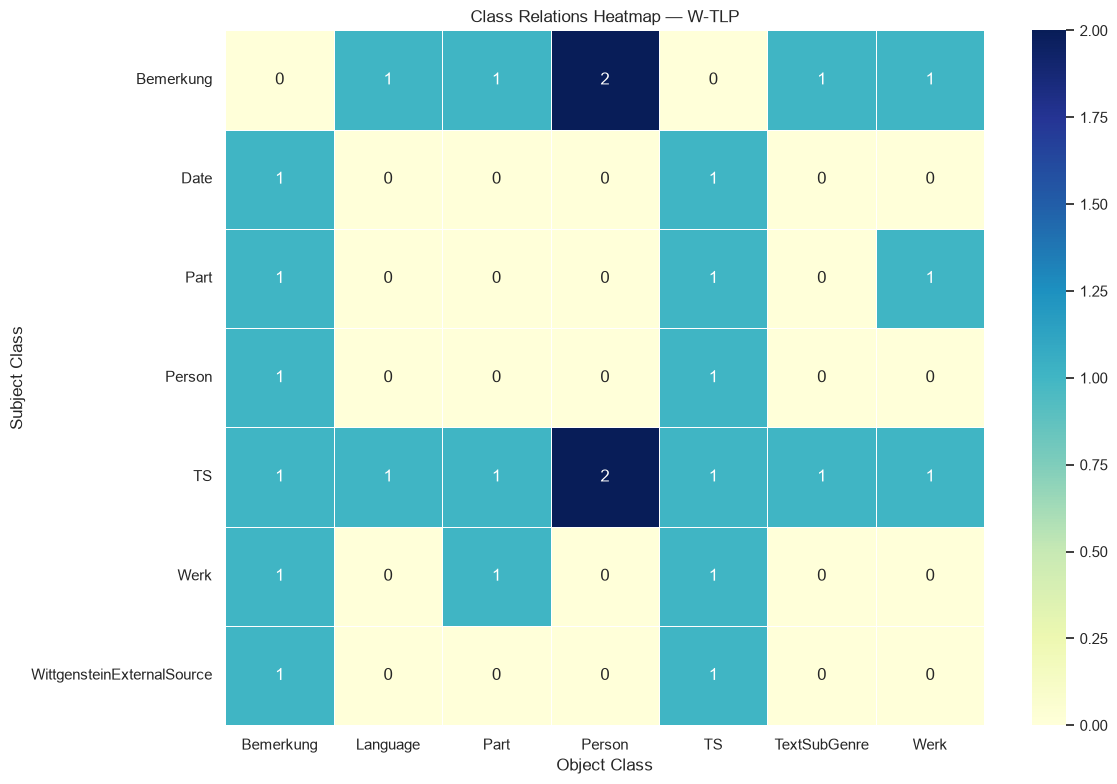

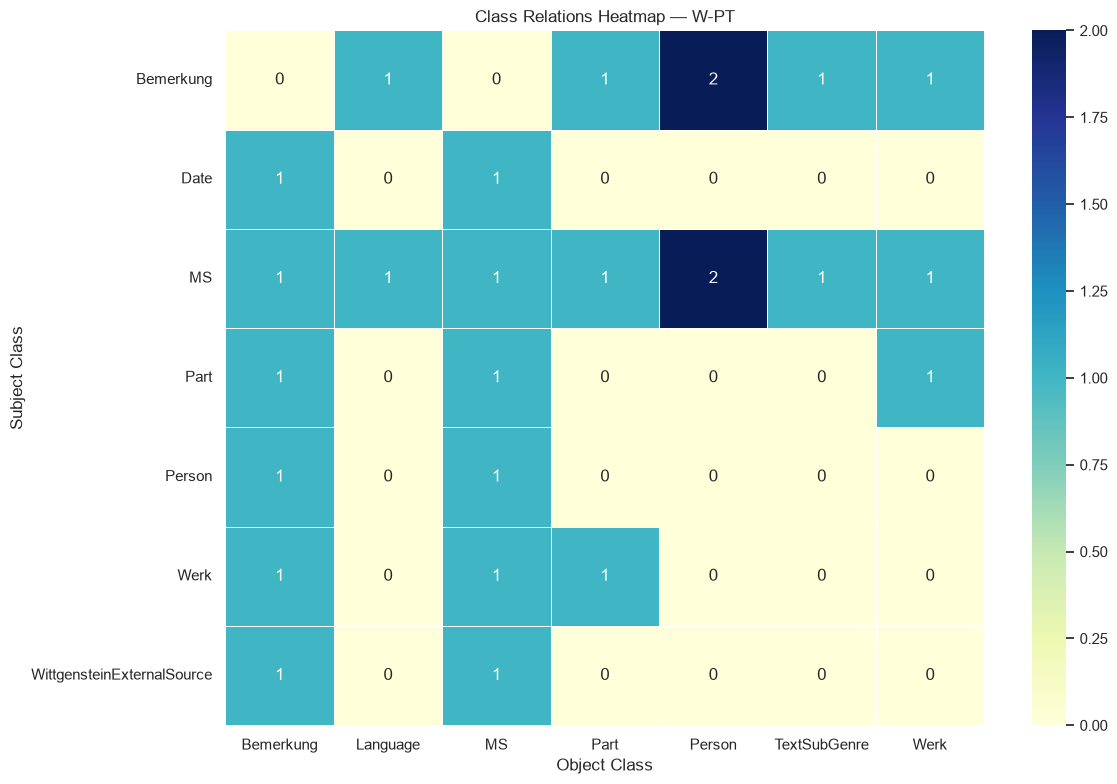

In [52]:
for work_name in relations_df["work"].unique():
    work_data = relations_df[relations_df["work"] == work_name]

    heatmap_data = work_data.pivot_table(
        index="subject_class",
        columns="object_class",
        values="predicate",
        aggfunc="count",
        fill_value=0
    )

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        linewidths=0.5
    )

    plt.title(f"Class Relations Heatmap — {work_name}")
    plt.xlabel("Object Class")
    plt.ylabel("Subject Class")
    plt.tight_layout()
    plt.show()

In [53]:
predicate_counts = (
    relations_df
    .groupby(["work", "predicate"])
    .size()
    .reset_index(name="number_of_relations")
    .sort_values(["work", "number_of_relations"], ascending=[True, False])
)

display(predicate_counts)

,work,predicate,number_of_relations
5,W-PT,isPublishedInWork,4
6,W-PT,isReferredToIn,4
7,W-PT,isWorkPublishedFrom,4
2,W-PT,hasPart,3
0,W-PT,contains,2
1,W-PT,hasAuthor,2
3,W-PT,isDateOf,2
8,W-PT,language,2
9,W-PT,refersTo,2
4,W-PT,isPartOf,1


In [54]:
tlp_relations = set(
    map(tuple, relations_df[relations_df["work"] == "W-TLP"]
        [["subject_class", "predicate", "object_class"]].values)
)

pt_relations = set(
    map(tuple, relations_df[relations_df["work"] == "W-PT"]
        [["subject_class", "predicate", "object_class"]].values)
)

common_relations = tlp_relations & pt_relations
only_tlp = tlp_relations - pt_relations
only_pt = pt_relations - tlp_relations

print("Common relations:", len(common_relations))
print("Only in W-TLP:", len(only_tlp))
print("Only in W-PT:", len(only_pt))

Common relations: 13
Only in W-TLP: 13
Only in W-PT: 13


In [56]:
print("Common relations:")
for relation in sorted(common_relations):
    print(relation)

Common relations:
('Bemerkung', 'contains', 'TextSubGenre')
('Bemerkung', 'hasAuthor', 'Person')
('Bemerkung', 'isPublishedInWork', 'Part')
('Bemerkung', 'isPublishedInWork', 'Werk')
('Bemerkung', 'language', 'Language')
('Bemerkung', 'refersTo', 'Person')
('Date', 'isDateOf', 'Bemerkung')
('Part', 'isPartOf', 'Werk')
('Part', 'isWorkPublishedFrom', 'Bemerkung')
('Person', 'isReferredToIn', 'Bemerkung')
('Werk', 'hasPart', 'Part')
('Werk', 'isWorkPublishedFrom', 'Bemerkung')
('WittgensteinExternalSource', 'isReferredToIn', 'Bemerkung')


In [57]:
print("\nOnly in W-TLP:")
for relation in sorted(only_tlp):
    print(relation)

print("\nOnly in W-PT:")
for relation in sorted(only_pt):
    print(relation)


Only in W-TLP:
('Date', 'isDateOf', 'TS')
('Part', 'isWorkPublishedFrom', 'TS')
('Person', 'isReferredToIn', 'TS')
('TS', 'contains', 'TextSubGenre')
('TS', 'hasAuthor', 'Person')
('TS', 'hasPart', 'Bemerkung')
('TS', 'hasPart', 'TS')
('TS', 'isPublishedInWork', 'Part')
('TS', 'isPublishedInWork', 'Werk')
('TS', 'language', 'Language')
('TS', 'refersTo', 'Person')
('Werk', 'isWorkPublishedFrom', 'TS')
('WittgensteinExternalSource', 'isReferredToIn', 'TS')

Only in W-PT:
('Date', 'isDateOf', 'MS')
('MS', 'contains', 'TextSubGenre')
('MS', 'hasAuthor', 'Person')
('MS', 'hasPart', 'Bemerkung')
('MS', 'hasPart', 'MS')
('MS', 'isPublishedInWork', 'Part')
('MS', 'isPublishedInWork', 'Werk')
('MS', 'language', 'Language')
('MS', 'refersTo', 'Person')
('Part', 'isWorkPublishedFrom', 'MS')
('Person', 'isReferredToIn', 'MS')
('Werk', 'isWorkPublishedFrom', 'MS')
('WittgensteinExternalSource', 'isReferredToIn', 'MS')


In [58]:
comparison_df = pd.DataFrame([
    {
        "subject_class": s,
        "predicate": p,
        "object_class": o,
        "W-TLP": "Yes" if (s, p, o) in tlp_relations else "No",
        "W-PT": "Yes" if (s, p, o) in pt_relations else "No"
    }
    for s, p, o in sorted(tlp_relations | pt_relations)
])

display(comparison_df)

,subject_class,predicate,object_class,W-TLP,W-PT
0,Bemerkung,contains,TextSubGenre,Yes,Yes
1,Bemerkung,hasAuthor,Person,Yes,Yes
2,Bemerkung,isPublishedInWork,Part,Yes,Yes
3,Bemerkung,isPublishedInWork,Werk,Yes,Yes
4,Bemerkung,language,Language,Yes,Yes
5,Bemerkung,refersTo,Person,Yes,Yes
6,Date,isDateOf,Bemerkung,Yes,Yes
7,Date,isDateOf,MS,No,Yes
8,Date,isDateOf,TS,Yes,No
9,MS,contains,TextSubGenre,No,Yes


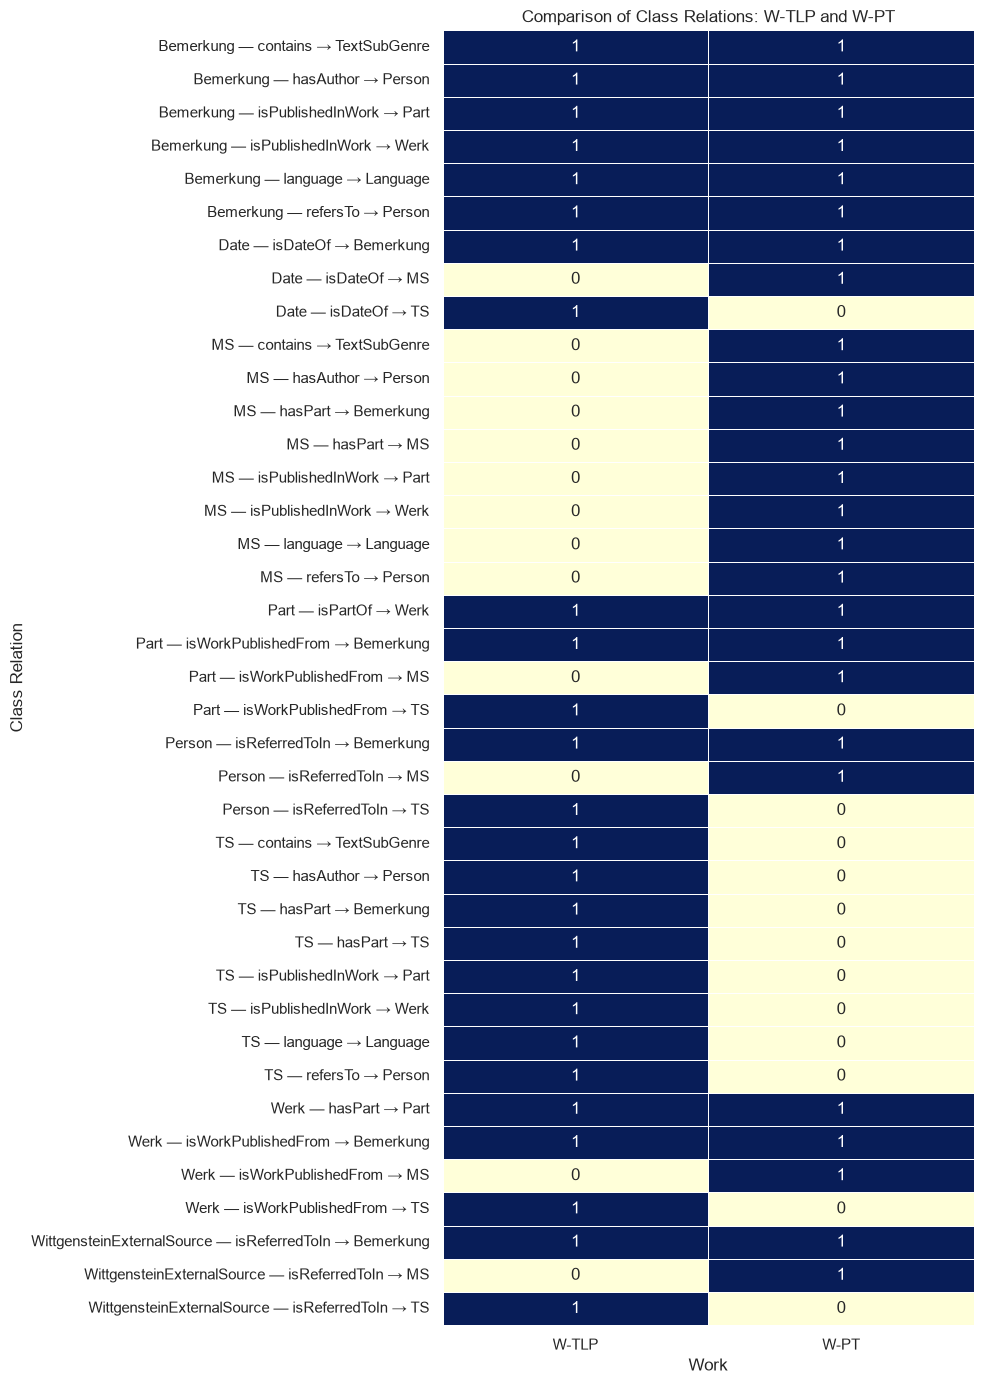

In [59]:
comparison_matrix = comparison_df.copy()

comparison_matrix["W-TLP"] = comparison_matrix["W-TLP"].map(
    {"Yes": 1, "No": 0}
)

comparison_matrix["W-PT"] = comparison_matrix["W-PT"].map(
    {"Yes": 1, "No": 0}
)

comparison_matrix["relation"] = (
    comparison_matrix["subject_class"] + " — " +
    comparison_matrix["predicate"] + " → " +
    comparison_matrix["object_class"]
)

heatmap_comparison = comparison_matrix.set_index("relation")[["W-TLP", "W-PT"]]

plt.figure(figsize=(10, 14))

sns.heatmap(
    heatmap_comparison,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar=False
)

plt.title("Comparison of Class Relations: W-TLP and W-PT")
plt.xlabel("Work")
plt.ylabel("Class Relation")
plt.tight_layout()
plt.show()

In [60]:
tlp_uri = works["W-TLP"]
pt_uri = works["W-PT"]

print("Outgoing relations from W-TLP to W-PT:")

for predicate in graph.predicates(tlp_uri, pt_uri):
    print(get_local_name(predicate))

print("\nOutgoing relations from W-PT to W-TLP:")

for predicate in graph.predicates(pt_uri, tlp_uri):
    print(get_local_name(predicate))

Outgoing relations from W-TLP to W-PT:

Outgoing relations from W-PT to W-TLP:


In [61]:
print("W-TLP properties:")

for predicate in set(graph.predicates(tlp_uri)):
    print(get_local_name(predicate))

print("\nW-PT properties:")

for predicate in set(graph.predicates(pt_uri)):
    print(get_local_name(predicate))

W-TLP properties:
notation
hasPart
label
isWorkPublishedFrom
identifier
type

W-PT properties:
notation
hasPart
label
isWorkPublishedFrom
identifier
type


In [62]:
tlp_resources = set(graph.objects(tlp_uri, HAS_PART))
pt_resources = set(graph.objects(pt_uri, HAS_PART))

common_resources = tlp_resources & pt_resources

print("Common parts:", len(common_resources))

for resource in sorted(common_resources, key=str):
    print(get_local_name(resource))

Common parts: 0


In [63]:
tlp_resources = {
    resource
    for triple in relations_by_work["W-TLP"]
    for resource in (triple[0], triple[2])
}

pt_resources = {
    resource
    for triple in relations_by_work["W-PT"]
    for resource in (triple[0], triple[2])
}

common_resources = tlp_resources & pt_resources

print("Common resources:", len(common_resources))

for resource in sorted(common_resources, key=str):
    print(
        get_local_name(resource),
        "|",
        [get_local_name(t) for t in graph.objects(resource, RDF.type)]
    )

Common resources: 38
1918-07-01 | []
1918-08-31 | []
deu | ['Language']
graphicnotation | ['TextSubGenre']
19180701%3F-19180831%3F | ['Date']
C%C3%A4sar__Gaius_Julius | ['Person']
Ernst__Paul | ['Person']
Ernst__Paul__Nachwort_zu_Kinder-_und_Hausm%C3%A4rchen | ['WittgensteinExternalSource']
Frege__Gottlob | ['Person']
Frege__Gottlob__%C3%9Cber_Sinn_und_Bedeutung | ['WittgensteinExternalSource']
Frege__Gottlob__Begriffsschrift | ['WittgensteinExternalSource']
Frege__Gottlob__Grundgesetze_der_Arithmetik | ['WittgensteinExternalSource']
Grimm__Jacob%3B_Grimm__Wilhelm | ['Person']
Grimm__Jacob__Grimm__Wilhelm__Die_Goldkinder | ['WittgensteinExternalSource']
Hertz__Heinrich | ['Person']
Hertz__Heinrich__Prinzipien_der_Mechanik_in_neuem_Zusammenhange_dargestellt | ['WittgensteinExternalSource']
K%C3%BCrnberger__Ferdinand | ['Person']
Kant__Immanuel | ['Person']
Kant__Immanuel__Prolegomena | ['WittgensteinExternalSource']
Mauthner__Fritz | ['Person']
Moore__George_Edward | ['Person']
Newton__

In [64]:
common_resource_types = []

for resource in common_resources:
    types = list(graph.objects(resource, RDF.type))

    if not types:
        common_resource_types.append({
            "resource": get_local_name(resource),
            "class": "No RDF type"
        })
    else:
        for resource_type in types:
            common_resource_types.append({
                "resource": get_local_name(resource),
                "class": get_local_name(resource_type)
            })

common_resources_df = pd.DataFrame(common_resource_types)

display(
    common_resources_df
    .groupby("class")
    .size()
    .reset_index(name="number_of_resources")
    .sort_values("number_of_resources", ascending=False)
)

,class,number_of_resources
3,Person,18
5,WittgensteinExternalSource,11
4,TextSubGenre,5
2,No RDF type,2
1,Language,1
0,Date,1


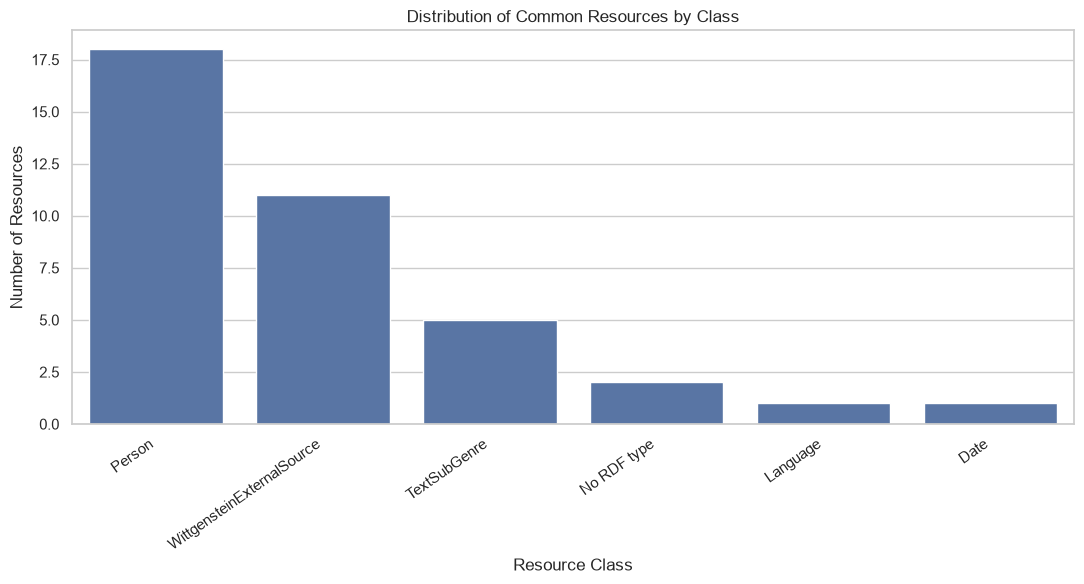

In [65]:
resource_counts = (
    common_resources_df
    .groupby("class")
    .size()
    .reset_index(name="number_of_resources")
    .sort_values("number_of_resources", ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=resource_counts,
    x="class",
    y="number_of_resources"
)

plt.title("Distribution of Common Resources by Class")
plt.xlabel("Resource Class")
plt.ylabel("Number of Resources")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [68]:
resource_connections = []

for resource in common_resources:
    for work_name, work_uri in works.items():

        for subject, predicate, obj in graph.triples((resource, None, None)):
            if obj == work_uri:
                resource_connections.append({
                    "work": work_name,
                    "resource": get_local_name(resource),
                    "direction": "resource → work",
                    "predicate": get_local_name(predicate)
                })

        for subject, predicate, obj in graph.triples((None, None, resource)):
            if subject == work_uri:
                resource_connections.append({
                    "work": work_name,
                    "resource": get_local_name(resource),
                    "direction": "work → resource",
                    "predicate": get_local_name(predicate)
                })

resource_connections_df = pd.DataFrame(resource_connections)

print("Number of direct connections:", len(resource_connections_df))
display(resource_connections_df)

Number of direct connections: 0


""


In [69]:
tlp_neighborhood = {
    resource
    for triple in relations_by_work["W-TLP"]
    for resource in (triple[0], triple[2])
}

pt_neighborhood = {
    resource
    for triple in relations_by_work["W-PT"]
    for resource in (triple[0], triple[2])
}

print("W-TLP neighborhood:", len(tlp_neighborhood))
print("W-PT neighborhood:", len(pt_neighborhood))

W-TLP neighborhood: 7764
W-PT neighborhood: 5358


In [70]:
indirect_connections = []

for resource in common_resources:
    for work_name, work_uri in works.items():

        # Find resources directly connected to the work
        for _, predicate1, intermediate in graph.triples((work_uri, None, None)):
            if intermediate == resource:
                continue

            # Check whether the intermediate resource connects to a common resource
            for predicate2 in graph.predicates(intermediate, resource):
                indirect_connections.append({
                    "work": work_name,
                    "intermediate": get_local_name(intermediate),
                    "relation_1": get_local_name(predicate1),
                    "common_resource": get_local_name(resource),
                    "relation_2": get_local_name(predicate2)
                })

        # Check incoming connections to the work
        for intermediate, predicate1, _ in graph.triples((None, None, work_uri)):
            if intermediate == resource:
                continue

            for predicate2 in graph.predicates(intermediate, resource):
                indirect_connections.append({
                    "work": work_name,
                    "intermediate": get_local_name(intermediate),
                    "relation_1": get_local_name(predicate1),
                    "common_resource": get_local_name(resource),
                    "relation_2": get_local_name(predicate2)
                })

indirect_connections_df = pd.DataFrame(indirect_connections)

print("Number of indirect connections:", len(indirect_connections_df))
display(indirect_connections_df.head(20))

Number of indirect connections: 8196


,work,intermediate,relation_1,common_resource,relation_2
0,W-TLP,Ts-202%2C32r%5B1%5D_d,isWorkPublishedFrom,Russell__Bertrand%3B_Whitehead__Alfred_North,refersTo
1,W-TLP,Ts-203%2C35r%5B2%5D_d,isWorkPublishedFrom,Russell__Bertrand%3B_Whitehead__Alfred_North,refersTo
2,W-TLP,Ts-203%2C41r%5B8%5D_d,isWorkPublishedFrom,Russell__Bertrand%3B_Whitehead__Alfred_North,refersTo
3,W-TLP,Ts-204%2C32r%5B1%5D_d,isWorkPublishedFrom,Russell__Bertrand%3B_Whitehead__Alfred_North,refersTo
4,W-PT,Ms-104%2C39%5B3%5D_d,isWorkPublishedFrom,Russell__Bertrand%3B_Whitehead__Alfred_North,refersTo
5,W-TLP,Ts-203%2C13r%5B7%5D_d,isWorkPublishedFrom,music,contains
6,W-PT,Ms-104%2C25%5B12%5Det26%5B1%5D_d,isWorkPublishedFrom,music,contains
7,W-TLP,Ts-202%2CIr%5B2%5D_d,isWorkPublishedFrom,preface,contains
8,W-TLP,Ts-202%2CIr%5B3%5D_d,isWorkPublishedFrom,preface,contains
9,W-TLP,Ts-202%2CIr%5B4%5D_d,isWorkPublishedFrom,preface,contains


In [71]:
indirect_summary = (
    indirect_connections_df
    .groupby(
        ["work", "common_resource", "relation_2"],
        as_index=False
    )
    .agg(
        number_of_paths=("intermediate", "nunique"),
        intermediate_resources=("intermediate", "count")
    )
    .sort_values(
        ["common_resource", "work"]
    )
)

display(indirect_summary)

,work,common_resource,relation_2,number_of_paths,intermediate_resources
0,W-PT,1918-07-01,madeAfter,78,78
21,W-TLP,1918-07-01,madeAfter,1094,1132
1,W-PT,1918-08-31,madeBefore,79,79
22,W-TLP,1918-08-31,madeBefore,1094,1132
2,W-PT,Ernst__Paul,refersTo,1,1
23,W-TLP,Ernst__Paul,refersTo,3,6
3,W-PT,Frege__Gottlob,refersTo,25,25
24,W-TLP,Frege__Gottlob,refersTo,46,46
4,W-PT,Grimm__Jacob%3B_Grimm__Wilhelm,refersTo,1,1
25,W-TLP,Grimm__Jacob%3B_Grimm__Wilhelm,refersTo,3,3


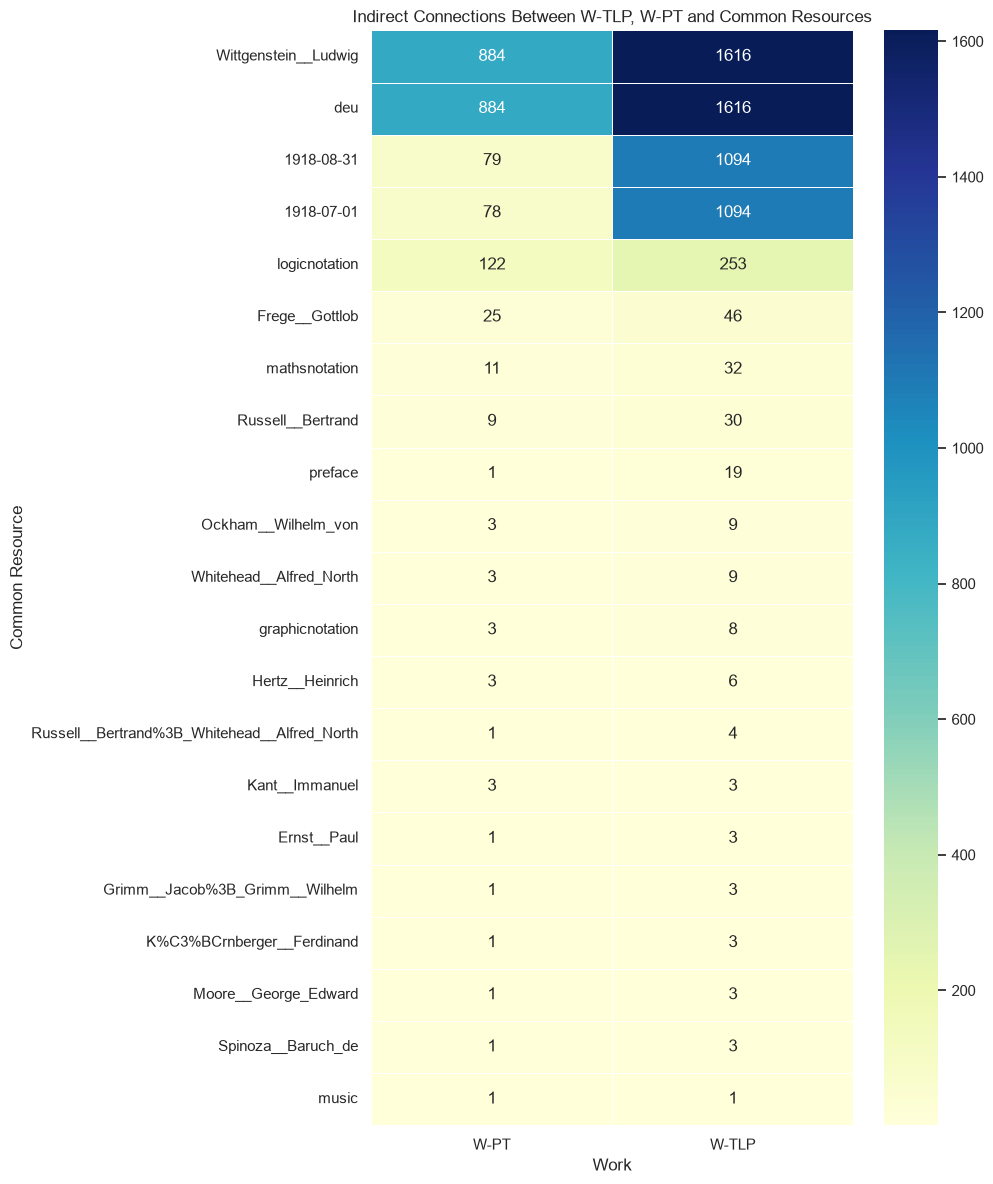

In [72]:
resource_heatmap = indirect_summary.pivot_table(
    index="common_resource",
    columns="work",
    values="number_of_paths",
    fill_value=0
)

resource_heatmap = resource_heatmap.sort_values(
    by=["W-TLP", "W-PT"],
    ascending=False
)

plt.figure(figsize=(10, 12))

sns.heatmap(
    resource_heatmap,
    annot=True,
    fmt="g",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Indirect Connections Between W-TLP, W-PT and Common Resources")
plt.xlabel("Work")
plt.ylabel("Common Resource")

plt.tight_layout()
plt.show()

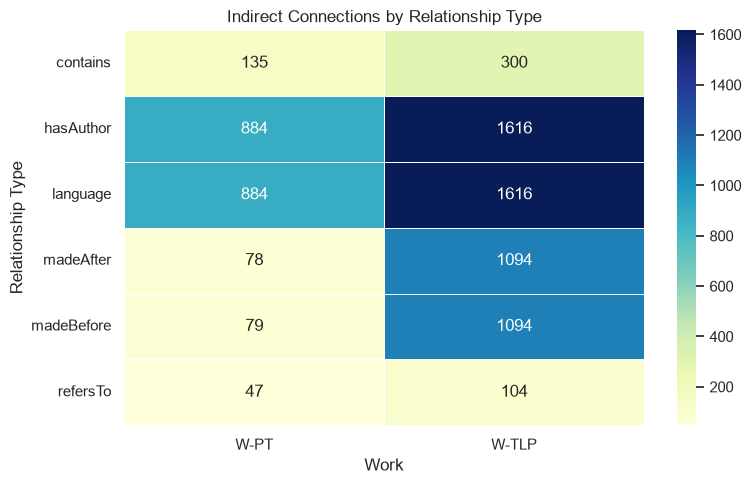

In [73]:
relation_heatmap = indirect_connections_df.pivot_table(
    index="relation_2",
    columns="work",
    values="intermediate",
    aggfunc="nunique",
    fill_value=0
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    relation_heatmap,
    annot=True,
    fmt="g",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Indirect Connections by Relationship Type")
plt.xlabel("Work")
plt.ylabel("Relationship Type")

plt.tight_layout()
plt.show()